# 5.1 Understanding Representation Learning

**Module 5 · Note 1**

Up to now, almost every model you have built started from data that was already in a convenient shape: a table where each column was a meaningful measurement such as age, income or number of purchases. Someone had already decided *what to measure*. The model's job was only to combine those measurements into a prediction.

Most of the data in the world does not arrive like that. A photograph arrives as hundreds of thousands of brightness values. A sentence arrives as a string of characters. A recording arrives as air-pressure readings sampled thousands of times a second. None of these raw numbers is meaningful on its own. A single pixel tells you almost nothing about whether a photo shows a shoe or a shirt.

This note is about the idea that makes Deep Learning work on data like this: instead of a person deciding which measurements matter, the network **learns its own measurements** from the raw data. Those learned measurements are called a **representation**, and the process is called **representation learning**. Every other note in Module 5, from CNNs to text embeddings to CLIP, is a variation on this one idea.

**Key question:** *What changes when a network learns its own features instead of being given them?*

**By the end of this note you will be able to:**
- explain what a representation is and why raw data needs one;
- describe a network as an *encoder* that builds a representation and a *head* that uses it;
- compare handcrafted features, raw inputs and learned representations on the same task, with measured results;
- explain why a good representation makes later tasks easier, especially when labelled data is scarce.

**Before you start:** you should be comfortable with building and training a small `nn.Module` in PyTorch, splitting data into training and validation sets, and fitting a logistic-regression classifier with scikit-learn. Nothing else is assumed.

### Setup

Run the cell below first. It imports the libraries used throughout this note and fixes the random seeds, so that your numbers match the ones written in this note. It also checks whether a GPU is available. Everything in this note runs comfortably on a CPU.

In [1]:
import os, gzip, urllib.request
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.1+cu130 | device: cpu


## 1. What Is Representation Learning?

Let's start with a question that sounds almost too simple: **what does a computer actually receive when you give it a photo?**

We will use **Fashion-MNIST** throughout this module. It is a collection of small greyscale photos of clothing items, each labelled with one of ten categories such as *Trouser*, *Sneaker* or *Bag*. It was created as a slightly harder replacement for the famous handwritten-digit dataset MNIST, and it is small enough to train on a laptop in minutes. In this note we only need its 60,000 training images.

The cell below downloads the training images and labels (only the first time you run it) and loads them into NumPy arrays.

In [2]:
DATA_DIR = "data/fashion"
BASE_URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
FILES = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz"]

os.makedirs(DATA_DIR, exist_ok=True)
for f in FILES:
    path = os.path.join(DATA_DIR, f)
    if not os.path.exists(path):
        urllib.request.urlretrieve(BASE_URL + f, path)

def read_idx(path, offset):
    with gzip.open(path) as fh:
        return np.frombuffer(fh.read(), dtype=np.uint8, offset=offset)

for f in FILES:
    print(f"{f}: {os.path.getsize(os.path.join(DATA_DIR, f)) / 1024:,.0f} KB")

images = read_idx(os.path.join(DATA_DIR, FILES[0]), 16).reshape(-1, 28, 28)
labels = read_idx(os.path.join(DATA_DIR, FILES[1]), 8)
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
print("images:", images.shape, images.dtype)
print("labels:", labels.shape, "| classes:", len(CLASSES))

train-images-idx3-ubyte.gz: 25,803 KB
train-labels-idx1-ubyte.gz: 29 KB


images: (60000, 28, 28) uint8
labels: (60000,) | classes: 10


The output tells us that `images` has shape `(60000, 28, 28)`: sixty thousand images, each a grid of 28 rows by 28 columns. The `dtype` is `uint8`, which means each entry is a whole number from 0 to 255. There are 60,000 labels, one per image, covering the 10 classes.

Now let's look inside a single image. The first image in the dataset is an ankle boot. Here is a small window of it, rows 8 to 15 and columns 8 to 19, printed exactly as the computer stores it:

In [3]:
img = images[0]
print("Label:", CLASSES[labels[0]])
print("Smallest value:", img.min(), "| largest value:", img.max())
print(img[8:16, 8:20])

Label: Ankle boot
Smallest value: 0 | largest value: 255
[[  0   1   1   1   0 200 232 232 233 229 223 223]
 [  0   0   0   0   0 183 225 216 223 228 235 227]
 [  0   0   0   0   0 193 228 218 213 198 180 212]
 [  0   1   3   0  12 219 220 212 218 192 169 227]
 [  0   0   6   0  99 244 222 220 218 203 198 221]
 [  0   4   0   0  55 236 228 230 228 240 232 213]
 [  0   0   0   0 237 226 217 223 222 219 222 221]
 [  0  62 145 204 228 207 213 221 218 208 211 218]]


Each number is the brightness of one **pixel** (short for *picture element*, one tiny square of the image): 0 is black, 255 is white. That is *all* the computer has. There is no "boot" anywhere in these numbers, no "heel", no "laces". There are only 784 brightness values (28 × 28) arranged in a grid.

To make this concrete, the figure below shows the whole image as we see it on the left, and the window inside the orange box as the computer sees it on the right.

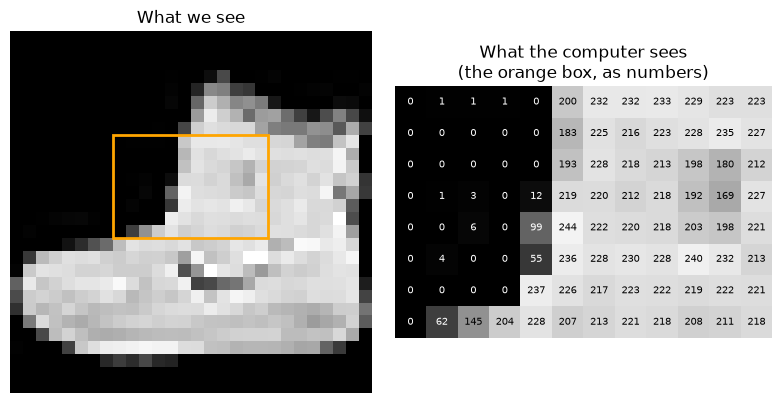

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img, cmap="gray")
axes[0].set_title("What we see")
axes[0].add_patch(plt.Rectangle((7.5, 7.5), 12, 8, fill=False, edgecolor="orange", lw=2))
axes[1].imshow(img[8:16, 8:20], cmap="gray", vmin=0, vmax=255)
for (r, c), v in np.ndenumerate(img[8:16, 8:20]):
    axes[1].text(c, r, int(v), ha="center", va="center", fontsize=7,
                 color="white" if v < 128 else "black")
axes[1].set_title("What the computer sees\n(the orange box, as numbers)")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

You can recognise the boot instantly. But notice what your brain did: it ignored individual brightness values and picked out *edges*, *shapes* and *parts*, then combined them into "boot". Those are not in the data. They are a **description you built from the data**.

Text has exactly the same problem. A sentence reaches the computer as a sequence of characters, and each character is stored as a number (its *Unicode code point*, a standard numbering of every character in every writing system):

In [5]:
sentence = "This film was surprisingly good."
print(list(sentence)[:10])
print([ord(ch) for ch in sentence][:10])
print("characters:", len(sentence))

['T', 'h', 'i', 's', ' ', 'f', 'i', 'l', 'm', ' ']
[84, 104, 105, 115, 32, 102, 105, 108, 109, 32]
characters: 32


The sentence has 32 characters, and the capital `T` is stored as 84. Nothing in the number 84 says "this word is positive about a film". Meaning is not in the raw symbols; it has to be built from them.

This is the core problem representation learning solves. We can now define the key term properly.

> **Key terms**
> - **Raw data:** data in the form it was recorded: pixels, characters, audio samples. Individually, these values carry little meaning.
> - **Feature:** a single number that describes something useful about an example, such as "how tall is the object in this image?"
> - **Representation:** the full list of features used to describe an example. Think of it as the *description* the model works from. A representation is usually a vector (a list of numbers), so you will also hear it called a **feature vector**, and for text and other discrete things, an **embedding**.
> - **Representation learning:** training a model so that it *discovers* useful features from raw data by itself, instead of a person designing them.

A helpful way to picture this: imagine describing a stranger to a friend so they can spot them in a crowd. Listing the colour of every square centimetre of their clothing would be accurate but useless. "Tall, red jacket, curly hair, carrying a guitar" is far shorter and far more useful. A good representation is like that second description: compact, and focused on what matters for the task.

> 🖼 *IMAGE 5.1.1 — Same Thing, Two Descriptions.* A two-panel illustration on a white background. Left panel titled "Raw description": a small photo-style drawing of an ankle boot with a fine grid laid over it, and beside it a long scrolling column of numbers (e.g. "0, 1, 1, 0, 200, 232, 232 …") trailing off the bottom of the panel, labelled "784 brightness values". Right panel titled "Useful description": the same boot with three short labelled tags pointing at it: "tall shape", "heel at bottom-left", "closed top", and below it a short vector "[0.9, 0.1, 0.8, …]" labelled "a few meaningful numbers". A thin arrow between the panels labelled "representation learning". Flat educational style, muted colours, sans-serif labels. Takeaway: a representation replaces many meaningless numbers with fewer meaningful ones.

> **Check yourself 1.** A colour photo is 1,000 pixels wide and 1,000 pixels tall, with three numbers (red, green, blue) per pixel. How many raw numbers does the computer receive, and why would feeding them directly to a simple model be difficult?

## 2. The Big Picture: From Raw Data to Learned Representations

Now that we know what the problem is, let's see the overall shape of the solution before we look at any details.

Every deep-learning model in this module can be read as two parts working one after the other:

1. An **encoder** takes raw data and turns it into a representation. In a neural network, the encoder is simply the early layers. Each layer transforms the numbers it receives into a new set of numbers, and the output of the last encoder layer is the representation.
2. A **head** takes the representation and turns it into the final answer: a class, a score, a next word. The head is usually small, often a single linear layer, because if the representation is good, the final step should be easy.

Both parts are trained *together* with the same loss and the same backpropagation you already know. Nobody tells the encoder which features to build. It builds whatever features make the head's job easiest, because those are the features that reduce the loss.

> 🖼 *IMAGE 5.1.2 — Encoder and Head.* A horizontal left-to-right flow diagram on a white background. Far left: a small grey 28×28 pixel image of a sneaker labelled "raw data (784 numbers)". Arrow into a tall blue trapezoid that narrows from left to right, labelled "ENCODER (early layers)". Out of its narrow end comes a short vertical stack of 6 coloured cells labelled "representation (e.g. 128 numbers)". Arrow into a small orange rectangle labelled "HEAD (e.g. one linear layer)". Arrow to a bar chart of 10 thin bars with the tallest labelled "Sneaker". Underneath the whole diagram, a long thin red arrow pointing right-to-left from the output back to the encoder, labelled "one loss, one backward pass: trains both parts together". Takeaway: the encoder builds the description, the head uses it, and both learn from the same error signal.

This split is worth remembering because it explains a lot of what comes later in the course:

- **CNNs** (Note 5.2) are encoders designed for images.
- **Embedding layers** (Note 5.3) are encoders for words and other symbols.
- **Pretrained models** (Module 7) are encoders that someone else has already trained on enormous datasets, which you can reuse with your own head.
- **Fine-tuning** (Module 8) is the process of adjusting a pretrained encoder for your task.

In the rest of this note, we will build all three kinds of description for Fashion-MNIST: features a person designs by hand, the raw pixels themselves, and features a network learns. Then we will compare them fairly.

> **Key terms**
> - **Encoder:** the part of a network that turns raw input into a representation.
> - **Head:** the final part of a network that turns a representation into the output the task needs.
> - **Downstream task:** any task that *uses* a representation as its input, such as classification, search or clustering.

> **Check yourself 2.** In the encoder–head picture, why does the head usually need only a single linear layer?

## 3. Feature Engineering vs. Representation Learning: A Shift, Not an Elimination

Before deep learning became practical, the standard way to handle images was **feature engineering**: an expert studied the problem and wrote code to compute features they believed would be useful. You have done this in classical machine learning: creating ratios, flags and aggregates from raw columns. Let's try it for clothing images, so we have something concrete to compare against.

### 3.1 Setting up a fair comparison

To compare different representations fairly, we need to use the data carefully. We split the 60,000 training images into three non-overlapping groups, each with a different job:

In [6]:
X = images.astype(np.float32) / 255.0
y = labels.astype(np.int64)

rep_idx   = np.arange(0, 40000)      # used to LEARN a representation
probe_idx = np.arange(40000, 50000)  # labelled examples for downstream classifiers
val_idx   = np.arange(50000, 60000)  # held out for measuring accuracy
print(len(rep_idx), len(probe_idx), len(val_idx))

40000 10000 10000


- **40,000 images (`rep_idx`)** are used only to *train a network* so it can learn a representation.
- **10,000 images (`probe_idx`)** are used to train the downstream classifier on top of each representation.
- **10,000 images (`val_idx`)** are never trained on. Every accuracy in this note is measured on them.

Keeping these groups separate means that no representation gets an unfair peek at the images it is judged on.

### 3.2 Designing features by hand

If you had to tell clothing items apart using only a few numbers, what would you measure? A sensible person might say: how much of the image is filled in, how tall and how wide the object is, whether it is taller than it is wide, whether the top or bottom half is heavier, and whether there is a dark gap down the middle (as there is between trouser legs). The function below computes exactly those seven features.

In [7]:
def handcrafted_features(X):
    ink = X.mean(axis=(1, 2))                     # how much of the image is "on"
    on = X > 0.2
    height = on.any(axis=2).sum(axis=1)           # rows containing the object
    width  = on.any(axis=1).sum(axis=1)           # columns containing the object
    aspect = height / np.maximum(width, 1)
    top_minus_bottom = X[:, :14].mean(axis=(1, 2)) - X[:, 14:].mean(axis=(1, 2))
    left_minus_right = X[:, :, :14].mean(axis=(1, 2)) - X[:, :, 14:].mean(axis=(1, 2))
    centre_gap = X[:, 14:, 12:16].mean(axis=(1, 2))  # e.g. the gap between trouser legs
    return np.stack([ink, height, width, aspect,
                     top_minus_bottom, left_minus_right, centre_gap], axis=1)

H = handcrafted_features(X)
names = ["ink", "height", "width", "aspect", "top-bottom", "left-right", "centre gap"]
print("handcrafted shape:", H.shape)
for c in [1, 7, 8]:
    row = H[y == c].mean(axis=0)
    print(f"{CLASSES[c]:<11}", "  ".join(f"{n}={v:.2f}" for n, v in zip(names, row)))

handcrafted shape: (60000, 7)
Trouser     ink=0.22  height=27.90  width=11.62  aspect=2.46  top-bottom=0.06  left-right=-0.01  centre gap=0.37
Sneaker     ink=0.17  height=12.80  width=27.39  aspect=0.47  top-bottom=-0.11  left-right=-0.09  centre gap=0.26
Bag         ink=0.35  height=23.17  width=25.44  aspect=0.96  top-bottom=-0.20  left-right=-0.02  centre gap=0.56


Each image is now described by just 7 numbers instead of 784. The printed averages show that some of these features genuinely carry information. Trousers are tall and narrow: on average 27.90 pixels tall but only 11.62 wide, an aspect ratio of 2.46. Sneakers are the reverse: 12.80 tall, 27.39 wide, an aspect ratio of 0.47. A person's intuition has produced real signal.

But look at the "centre gap" feature, which was meant to pick out the dark space between trouser legs. Sneakers score lower (0.26) than trousers (0.37). The idea was reasonable, yet in the data it does not behave the way its designer expected. This is the typical story of feature engineering: some features work, some don't, and you only find out by measuring.

### 3.3 Measuring how useful a representation is

To compare representations, we give each one to the **same simple classifier**: a logistic regression, with the features standardised first (rescaled to mean 0 and standard deviation 1, so that no feature dominates just because its numbers are larger). This is called a **linear probe**. Because the classifier is deliberately simple, any difference in accuracy comes from the *representation*, not from a cleverer classifier.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def linear_probe(F_train, y_train, F_val, y_val):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    clf.fit(F_train, y_train)
    return clf.score(F_val, y_val)

R = X.reshape(len(X), -1)   # raw pixels: 784 numbers per image
acc_hand = linear_probe(H[probe_idx], y[probe_idx], H[val_idx], y[val_idx])
acc_raw  = linear_probe(R[probe_idx], y[probe_idx], R[val_idx], y[val_idx])
print(f"handcrafted (7 features):  {acc_hand:.3f}")
print(f"raw pixels (784 features): {acc_raw:.3f}")

handcrafted (7 features):  0.694
raw pixels (784 features): 0.803


With seven handcrafted features, the classifier reaches **0.694** validation accuracy. With all 784 raw pixels, it reaches **0.803**. Random guessing among 10 balanced classes would give about 0.1, so both are far better than chance, but the raw pixels beat the handcrafted features.

That may surprise you. Shouldn't the expert's carefully chosen features win? Not necessarily. Seven numbers throw away most of the information in the image, and the expert can only encode the patterns they think of. The raw pixels keep everything. Fashion-MNIST images are also centred and similarly sized, so a given pixel position tends to mean roughly the same thing across images, which helps a linear model on raw pixels more than it would on real-world photos.

### 3.4 Letting a network learn the features

Now we try the third option. We train a small network, a **multilayer perceptron** (MLP, the stack of fully connected layers you built in Module 2), on the 40,000 representation-learning images. It has one hidden layer of 128 units. We split it explicitly into an `encoder` and a `head`, exactly as in Section 2.

In [9]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU())
        self.head = nn.Linear(128, 10)
    def forward(self, x):
        return self.head(self.encoder(x))

torch.manual_seed(0)
model = MLP()
Xt = torch.tensor(X[rep_idx]); yt = torch.tensor(y[rep_idx])
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
for epoch in range(3):
    perm = torch.randperm(len(Xt))
    total, batches = 0.0, 0
    for i in range(0, len(Xt), 128):
        b = perm[i:i + 128]
        opt.zero_grad()
        loss = loss_fn(model(Xt[b]), yt[b])
        loss.backward()
        opt.step()
        total += loss.item(); batches += 1
    print(f"epoch {epoch + 1}: average training loss {total / batches:.3f}")

epoch 1: average training loss 0.654


epoch 2: average training loss 0.446


epoch 3: average training loss 0.404


The average training loss falls each epoch, so the network is learning as expected.

The interesting part comes next. After training, we **throw away the head**, keep the encoder, and use its 128 outputs as a new representation of every image. Then we give that representation to exactly the same linear probe as before.

In [10]:
with torch.no_grad():
    L = model.encoder(torch.tensor(X)).numpy()   # learned representation: 128 numbers per image
print("learned representation shape:", L.shape)
acc_learned = linear_probe(L[probe_idx], y[probe_idx], L[val_idx], y[val_idx])
print(f"handcrafted (7):   {acc_hand:.3f}")
print(f"raw pixels (784):  {acc_raw:.3f}")
print(f"learned (128):     {acc_learned:.3f}")

learned representation shape: (60000, 128)


handcrafted (7):   0.694
raw pixels (784):  0.803
learned (128):     0.868


The ranking is now clear:

| Representation | Numbers per image | Validation accuracy |
|---|---|---|
| Handcrafted features | 7 | 0.694 |
| Raw pixels | 784 | 0.803 |
| Learned by the MLP encoder | 128 | 0.868 |

The learned representation uses about a sixth as many numbers as the raw pixels, yet the same simple classifier does better with it. The network has found features that make the classes easier to separate with a straight line, which is exactly what a good representation should do.

Be precise about *why* the learned features won, because this is easy to overstate. The encoder had something the other two did not: it was trained on 40,000 additional labelled images. Representation learning does not create information from nothing. It **moves the work of finding good features from a person to the training process**, and that process needs data.

### 3.5 Why "a shift, not an elimination"

It is tempting to say that deep learning makes feature engineering obsolete. It does not. Look back at what *we* still decided in this section:

- We converted pixel values from 0–255 to 0–1 by dividing by 255.
- We chose a network with one hidden layer of 128 units and a ReLU activation.
- We decided how to split the data so the comparison was fair.

In later notes, these human decisions become even more important: CNNs build in the assumption that nearby pixels belong together, and tokenisers decide how text is chopped into pieces before any learning happens. The accurate statement is that **deep learning shifts much of the representation-building into the model, while people still design the conditions under which it is learned.**

> **Common mistake:** concluding that learned features are "better" in general. They were better *here*, on *this* task, given *40,000 extra labelled examples*. With very little data, or when an expert knows exactly what matters (for example, a physics formula), carefully designed features can still win. You saw a similar lesson in the gradient-boosting vs. neural-network comparison in Module 4.

> **Check yourself 3.** The MLP encoder was trained on 40,000 labelled images, but the linear probe on top of it used only the 10,000 probe images. Why would it be wrong to train the encoder on the 10,000 validation images as well?

## 4. How Networks Build Hierarchical Representations

We now know that a learned representation can beat raw pixels. The natural next question is: **what did the network actually learn?** Opening the box also leads us to one of the most important ideas in deep learning, the idea of a *hierarchy* of features.

### 4.1 Looking inside one layer

Each of the 128 hidden units in our encoder computes a weighted sum of all 784 pixels and then applies ReLU (which outputs the sum if it is positive and 0 otherwise). So a unit "switches on", meaning it outputs a value above zero, when an image matches the pattern in its weights.

We can investigate each unit in two ways: look at its weights directly, and find the images that switch it on most strongly. The cell below records every unit's output for every validation image and summarises what each unit responds to.

In [11]:
with torch.no_grad():
    acts = model.encoder(torch.tensor(X[val_idx])).numpy()   # (10000, 128): each unit's output per image
dead = (acts.max(axis=0) == 0).sum()
print(f"hidden units: {acts.shape[1]} | units that never switch on for any validation image: {dead}")

def unit_summary(k, top=50):
    order = np.argsort(-acts[:, k])[:top]          # the 50 images that switch unit k on the most
    top_labels = y[val_idx][order]
    counts = np.bincount(top_labels, minlength=10)
    return order, counts.argmax(), counts.max() / top

units = [k for k in np.argsort(-acts.mean(axis=0))[:8]]   # the 8 most active units
for k in units:
    _, c, share = unit_summary(k)
    print(f"unit {k:>3}: most of its top-50 images are '{CLASSES[c]}' ({share:.0%})")

live = [k for k in range(acts.shape[1]) if acts[:, k].max() > 0]
shares = np.array([unit_summary(k)[2] for k in live])
print(f"across all {len(live)} live units, the median top-50 share of one class is {np.median(shares):.0%}")
print(f"units whose top-50 images are at least 90% one class: {(shares >= 0.9).sum()}")

hidden units: 128 | units that never switch on for any validation image: 14
unit  45: most of its top-50 images are 'Pullover' (46%)
unit  19: most of its top-50 images are 'Coat' (52%)
unit 124: most of its top-50 images are 'T-shirt/top' (82%)
unit  82: most of its top-50 images are 'T-shirt/top' (68%)
unit  42: most of its top-50 images are 'Pullover' (60%)
unit 125: most of its top-50 images are 'Bag' (98%)
unit  78: most of its top-50 images are 'Coat' (54%)
unit  16: most of its top-50 images are 'T-shirt/top' (48%)
across all 114 live units, the median top-50 share of one class is 78%
units whose top-50 images are at least 90% one class: 36


A few things stand out.

First, **14 of the 128 units never switch on** for any validation image. These are **dead units**: their weighted sum is negative for every input, so ReLU always outputs 0, and they contribute nothing. This is a known side effect of ReLU, and it means our encoder is really using 114 units, not 128.

Second, many units have become **detectors for particular kinds of clothing**, even though nobody told them to. Unit 125 is the clearest: 98% of the 50 images that switch it on most are bags. Across all 114 live units, the typical (median) unit has 78% of its top-50 images from a single class, and 36 units reach at least 90%.

Third, the eight units we printed are the eight with the highest *average* output, and they are less specialised than typical (46% to 82%). That makes sense: units that switch on strongly for many images tend to respond to anything large and bright, such as tops, pullovers and coats, rather than to one class.

The figure below shows these eight units. The top row shows each unit's 784 weights arranged back into a 28×28 grid: red pixels push the unit on, blue pixels push it off. The bottom row is the average of the 50 images that switch that unit on most.

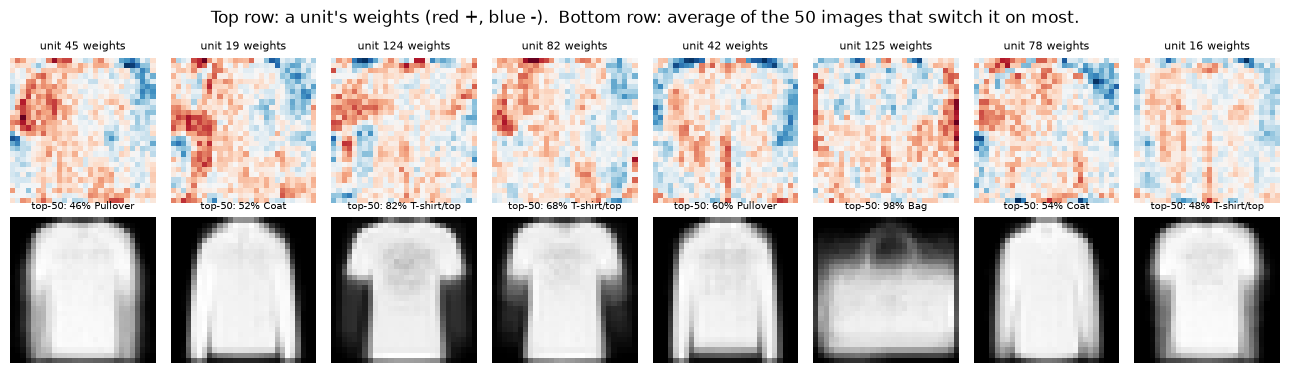

In [12]:
W = model.encoder[1].weight.detach().numpy()   # (128, 784): one row of 784 weights per hidden unit
fig, axes = plt.subplots(2, 8, figsize=(13, 3.8))
for j, k in enumerate(units):
    order, c, share = unit_summary(k)
    w = W[k].reshape(28, 28); m = np.abs(w).max()
    axes[0, j].imshow(w, cmap="RdBu_r", vmin=-m, vmax=m)
    axes[0, j].set_title(f"unit {k} weights", fontsize=8)
    axes[1, j].imshow(X[val_idx][order].mean(axis=0), cmap="gray")
    axes[1, j].set_title(f"top-50: {share:.0%} {CLASSES[c]}", fontsize=7)
for ax in axes.flat: ax.axis("off")
plt.suptitle("Top row: a unit's weights (red +, blue -).  Bottom row: average of the 50 images that switch it on most.")
plt.tight_layout(); plt.show()

The weight maps are noisy, but the averaged images make the pattern clear: each unit has become tuned to a whole-garment outline, such as a long-sleeved shape, a T-shirt shape or a bag with a handle.

### 4.2 Why one layer is not enough: hierarchy

Our encoder has only *one* layer, so each unit has to go straight from individual pixels to something like "bag-shaped". That is a big leap, and it is why the weight maps look like blurry whole-object templates. A template like that is fragile: shift the bag a few pixels to the left and the template no longer lines up.

Deeper networks avoid this by building understanding in **stages**, each stage reusing the features from the stage before:

- Early layers detect simple, local patterns: **edges** (places where brightness changes sharply) and small spots.
- Middle layers combine edges into **textures and parts**: a curve, a corner, a strap, a sole.
- Later layers combine parts into **whole objects**: "boot" is a sole, plus a tall shaft, plus a heel.

This layered structure is called a **hierarchical representation**. It is powerful because simple features can be **reused**: the same edge detector helps recognise a boot, a bag and a dress, so the network does not need to learn a separate template for every object in every position. Language works the same way: characters combine into words, words into phrases, phrases into meaning.

> 🖼 *IMAGE 5.1.3 — A Hierarchy of Features.* A four-column left-to-right diagram on a white background, with columns titled "Pixels", "Edges", "Parts", "Object". Column 1: a small greyscale ankle-boot image. Column 2: a 3×3 grid of tiny tiles, each showing a short line at a different angle (horizontal, vertical, diagonal) plus one small curve, labelled "layer 1: simple local patterns". Column 3: four slightly larger tiles showing a flat sole, a vertical shaft, a curved heel, and a rounded toe, labelled "layer 2–3: combinations of edges". Column 4: the boot outline assembled from those parts, labelled "later layers: whole objects". Thin grey arrows connect specific edge tiles to the parts they make up (e.g. the horizontal line and curve feed into "sole"). Along the bottom, a gradient bar from light to dark blue labelled "simple and local → complex and global". Takeaway: deep networks build complex features by combining simpler ones, layer by layer.

You will see this hierarchy directly in Note 5.2, where a convolutional network learns edge detectors in its first layer without being told to.

> **Key terms**
> - **Hidden unit (neuron):** one output of a hidden layer; a weighted sum of its inputs passed through an activation function.
> - **Dead unit:** a ReLU unit whose output is 0 for every input, so it never contributes or learns.
> - **Hierarchical representation:** a representation built in stages, where each layer combines the simpler features of the layer before it.

> **Check yourself 4.** Our one-layer encoder learned whole-garment templates. Give one reason why a template like this might fail if the same bag appeared slightly smaller or shifted to one side of the image.

## 5. Why Representation Quality Matters for Downstream Tasks

So far we have compared representations when the downstream classifier had plenty of labelled data: 10,000 examples. In real projects, labelled data is often the scarcest resource. Labels cost money, time and expert attention. So the most practical question about a representation is: **how much labelled data does it save you?**

To find out, we repeat the linear-probe experiment while giving the classifier fewer and fewer labelled examples: 20, 100, 500, 2,000 and 10,000. With very small samples the result depends heavily on *which* images happen to be chosen, so for every size below 10,000 we draw 5 different random samples and average the results. We also record the gap between the best and worst of the 5 draws, to see how noisy each estimate is.

In [13]:
sizes = [20, 100, 500, 2000, 10000]
repeats = 5                     # small samples are noisy, so we average 5 random draws
rng = np.random.default_rng(0)
results = {"handcrafted": [], "raw pixels": [], "learned": []}
spread = {k: [] for k in results}
for n in sizes:
    draws = [probe_idx] if n == len(probe_idx) else [rng.choice(probe_idx, n, replace=False) for _ in range(repeats)]
    for name, F in [("handcrafted", H), ("raw pixels", R), ("learned", L)]:
        accs = [linear_probe(F[s], y[s], F[val_idx], y[val_idx]) for s in draws]
        results[name].append(np.mean(accs)); spread[name].append(np.max(accs) - np.min(accs))
print("labelled examples:", sizes)
for name in results:
    print(f"{name:<12} mean acc:", "  ".join(f"{a:.3f}" for a in results[name]))
for name in results:
    print(f"{name:<12} max-min:  ", "  ".join(f"{a:.3f}" for a in spread[name]))

labelled examples: [20, 100, 500, 2000, 10000]
handcrafted  mean acc: 0.404  0.608  0.663  0.687  0.694
raw pixels   mean acc: 0.414  0.692  0.772  0.794  0.803
learned      mean acc: 0.562  0.794  0.830  0.855  0.868
handcrafted  max-min:   0.199  0.039  0.028  0.009  0.000
raw pixels   max-min:   0.192  0.061  0.014  0.007  0.000
learned      max-min:   0.161  0.040  0.005  0.010  0.000


Read the table row by row, then column by column.

- **With only 20 labelled examples** (about two per class), the learned representation reaches 0.562, against 0.414 for raw pixels and 0.404 for handcrafted features. But look at the spread row: the 5 draws differ by up to 0.161 to 0.199. With so few examples, a single lucky or unlucky draw moves the result a lot, which is exactly why we averaged.
- **With 100 labelled examples**, the learned representation reaches 0.794. Raw pixels need **2,000** labelled examples to reach the same accuracy (0.794). In other words, on this task the learned representation does the job with about **one twentieth of the labels**.
- **With 10,000 examples**, the handcrafted features level off at 0.694. Adding more labels hardly helps, because seven numbers simply cannot describe the differences between a shirt and a pullover. The *representation*, not the amount of data, has become the limit.

The plot shows the same results. The grey dashed line is chance level.

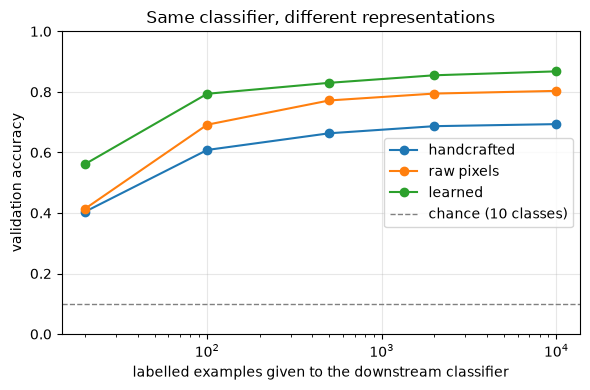

In [14]:
plt.figure(figsize=(6, 4))
for name, accs in results.items():
    plt.plot(sizes, accs, marker="o", label=name)
plt.xscale("log"); plt.xlabel("labelled examples given to the downstream classifier")
plt.axhline(0.1, color="grey", ls="--", lw=1, label="chance (10 classes)")
plt.ylabel("validation accuracy"); plt.ylim(0, 1); plt.grid(alpha=0.3); plt.legend()
plt.title("Same classifier, different representations"); plt.tight_layout(); plt.show()

This is the practical heart of representation learning. A good representation:

1. **reaches higher accuracy** with the same simple classifier;
2. **needs far fewer labels** to get there;
3. **can be reused**: we trained the encoder once, and could now attach many different heads to it for different tasks.

The third point is the foundation of modern AI engineering. In Module 7 you will use encoders that were trained on billions of examples, and attach your own small head, which is the same experiment as this one at a vastly larger scale.

> **Common mistake:** trusting a single small-sample result. With 20 labelled examples, the accuracy of one draw varied by close to 0.2 depending on which images were picked. Whenever your training set is small, repeat the experiment with different samples and report the average and the spread.

> **Check yourself 5.** The handcrafted curve is almost flat between 2,000 and 10,000 labelled examples. What does that tell you about where its errors are coming from?

## Putting It All Together

Let's reassemble the whole picture.

Raw data such as pixels and characters is plentiful but individually meaningless. To make predictions from it, a model needs a **representation**: a compact description that captures what matters for the task. There are three ways to get one, and we measured all three on the same 10,000 validation images using the same linear probe:

| Representation | How it was obtained | Numbers per image | Accuracy with 100 labels | Accuracy with 10,000 labels |
|---|---|---|---|---|
| Handcrafted | a person designed 7 features | 7 | 0.608 | 0.694 |
| Raw pixels | no processing | 784 | 0.692 | 0.803 |
| Learned | an MLP encoder trained on 40,000 other labelled images | 128 | 0.794 | 0.868 |

A network learns its representation by being split into an **encoder** and a **head** that are trained together. The encoder discovers whatever features make the head's job easiest. Inside, its units became detectors: one responded almost only to bags. A deeper network would build these detectors in a **hierarchy**, from edges to parts to objects, so that simple features can be reused.

The pay-off is **data efficiency and reuse**: the learned representation matched, with 100 labels, what raw pixels needed 2,000 labels to achieve. The cost is that learning the representation needed data of its own, plus human decisions about architecture, preprocessing and data splits. That is why we say deep learning *shifts* feature engineering rather than eliminating it.

> 🖼 *IMAGE 5.1.4 — Three Routes to a Representation.* A diagram with one input on the left: a small greyscale Fashion-MNIST sneaker labelled "raw image". Three horizontal paths branch out to the right, each ending at the same small orange box labelled "same linear classifier". Top path: a person icon with a pencil, then a short list "ink, height, width, aspect…" labelled "handcrafted: 7 numbers". Middle path: a straight arrow with a long thin strip of grey cells labelled "raw pixels: 784 numbers". Bottom path: a blue trapezoid labelled "learned encoder (trained on other labelled data)", then a stack of coloured cells labelled "learned: 128 numbers". To the right of each orange box, a small accuracy badge: top "0.694", middle "0.803", bottom "0.868" (these are the measured results with 10,000 labels). Takeaway: the classifier is the same; only the description changes, and the description decides the result.

## Summary

- Raw data such as pixels and characters arrives as many numbers that mean little individually. A Fashion-MNIST image is 784 brightness values from 0 to 255.
- A **representation** is the description a model works from; **representation learning** means the model discovers that description itself.
- Networks can be read as an **encoder** (builds the representation) and a **head** (uses it), trained together by one loss.
- On the same linear probe with 10,000 labels, handcrafted features scored 0.694, raw pixels 0.803 and a learned 128-number representation 0.868.
- Learned features won here because the encoder learned from 40,000 additional labelled images. Representation learning moves feature-building into training; it does not remove the need for data or human design choices.
- Units inside a trained encoder become detectors for meaningful patterns. Deeper networks organise these detectors **hierarchically**, from edges to parts to objects.
- Good representations are **data-efficient**: with 100 labels, the learned representation matched what raw pixels needed 2,000 labels to reach.
- Small-sample results are noisy; repeat them and report the spread.

## Glossary

| Term | Meaning |
|---|---|
| Raw data | Data in the form it was recorded: pixels, characters, audio samples. |
| Pixel | One tiny square of an image, stored as a brightness number (0–255 here). |
| Feature | A single number describing something useful about an example. |
| Representation | The list of features a model uses to describe an example; also called a feature vector. |
| Embedding | A learned representation, usually for discrete things such as words. |
| Representation learning | Training a model so that it discovers useful features from raw data. |
| Feature engineering | Designing features by hand, using human knowledge of the problem. |
| Encoder | The part of a network that turns raw input into a representation. |
| Head | The final part of a network that turns a representation into the task's output. |
| Downstream task | A task that uses a representation as its input. |
| Linear probe | A simple linear classifier trained on top of a fixed representation to measure how useful it is. |
| Standardise | Rescale each feature to mean 0 and standard deviation 1. |
| Hidden unit | One output of a hidden layer. |
| Dead unit | A ReLU unit that outputs 0 for every input. |
| Hierarchical representation | Features built in stages, each combining simpler features from the stage before. |
| Data efficiency | How few labelled examples a method needs to reach a given accuracy. |

## Answers to Check Yourself

**1.** 1,000 × 1,000 × 3 = 3 million numbers. Each number on its own says almost nothing about what is in the photo, and a simple model would have to work out from scratch how millions of numbers relate to one another. It would need enormous amounts of data and would be easily confused by changes such as lighting or position. A representation compresses this into a much smaller set of meaningful features.

**2.** Because the encoder has already done the hard work. If the representation separates the classes well, a straight-line decision boundary (a linear layer) is enough to read off the answer. If the head needs to be large and complicated, that is often a sign the representation is not good enough.

**3.** The validation images are supposed to be unseen, so that the accuracy we measure on them tells us how the method performs on new data. If the encoder had trained on them, it could have learned features tuned to those specific images, and the validation accuracy would be optimistic. This is data leakage: information from the evaluation set leaking into training.

**4.** The template lines up with particular pixel positions. If the bag is smaller or shifted, its outline falls on different pixels, so the weighted sum changes and the unit may not switch on. A hierarchical network that detects edges and parts wherever they appear is much less sensitive to this.

**5.** The errors are no longer caused by a lack of labelled examples; they are caused by the representation itself. Seven numbers cannot capture the differences between some classes (for example, shirt vs. pullover), so no amount of extra labels lets the classifier separate them. The representation has become the bottleneck.